# Automatic Helmet / No-Helmet YOLO11 Training — Google Colab

**No Roboflow. No API key. No manual dataset configuration or annotation.**

Run the notebook from top to bottom. It will:
1. Install dependencies.
2. Download the public Hugging Face dataset archive.
3. Extract and automatically locate the YOLO dataset.
4. Validate labels and class IDs.
5. Train YOLO11n for 50 epochs using a GPU when available.
6. Evaluate on validation and test splits.
7. Export `best.pt` and `helmet_nohelmet.onnx`.
8. Save weights, metrics, plots and metadata to Google Drive.

Dataset: [DeBoniz/helmet-detection-dataset](https://huggingface.co/datasets/DeBoniz/helmet-detection-dataset)  
Dataset card reports 18,159 images, YOLO annotations, classes `0=Helmet`, `1=No-Helmet`, and CC BY 4.0.

**Compatibility note:** the dataset card describes boxes for people/riders wearing or not wearing helmets; it does not guarantee the labels are head-only crops. Your existing repository's current helmet detector is used on person-context crops and expects head-level boxes. This notebook trains the dataset as published and saves a model, but it cannot magically change the annotation meaning. The exported model may require adapting the video pipeline's association logic or further head-level fine-tuning before it can replace the current detector. The notebook records this limitation in its metadata.

## 1. Install libraries

In [1]:
!pip -q install -U ultralytics onnx onnxruntime pyyaml

## 2. Check GPU and configure workspace

In [2]:
import os, sys, json, time, shutil, zipfile, random, collections, hashlib
from pathlib import Path
import requests, yaml, torch
from ultralytics import YOLO

WORK = Path("/content/helmet_training")
ARCHIVE = WORK / "helmet-detection-dataset.zip"
EXTRACT = WORK / "dataset"
RUNS = WORK / "runs"
WORK.mkdir(parents=True, exist_ok=True)
RUNS.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Training will be much slower. In Colab select a GPU runtime.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


## 3. Download dataset automatically from Hugging Face

In [3]:
DATASET_URL = "https://huggingface.co/datasets/DeBoniz/helmet-detection-dataset/resolve/main/helmet-detection-dataset.zip"

if not ARCHIVE.exists() or ARCHIVE.stat().st_size < 100_000_000:
    if ARCHIVE.exists():
        ARCHIVE.unlink()
    with requests.get(DATASET_URL, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0))
        downloaded = 0
        start = time.time()
        with open(ARCHIVE, "wb") as f:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if chunk:
                    f.write(chunk)
                    downloaded += len(chunk)
                    if total:
                        print(f"Downloaded {downloaded/1e9:.2f}/{total/1e9:.2f} GB", end="\\r")
    print(f"\\nDownload finished in {(time.time()-start)/60:.1f} minutes.")
else:
    print("Using existing archive:", ARCHIVE, f"({ARCHIVE.stat().st_size/1e9:.2f} GB)")

Downloaded 0.01/1.47 GB\rDownloaded 0.02/1.47 GB\rDownloaded 0.03/1.47 GB\rDownloaded 0.03/1.47 GB\rDownloaded 0.04/1.47 GB\rDownloaded 0.05/1.47 GB\rDownloaded 0.06/1.47 GB\rDownloaded 0.07/1.47 GB\rDownloaded 0.08/1.47 GB\rDownloaded 0.08/1.47 GB\rDownloaded 0.09/1.47 GB\rDownloaded 0.10/1.47 GB\rDownloaded 0.11/1.47 GB\rDownloaded 0.12/1.47 GB\rDownloaded 0.13/1.47 GB\rDownloaded 0.13/1.47 GB\rDownloaded 0.14/1.47 GB\rDownloaded 0.15/1.47 GB\rDownloaded 0.16/1.47 GB\rDownloaded 0.17/1.47 GB\rDownloaded 0.18/1.47 GB\rDownloaded 0.18/1.47 GB\rDownloaded 0.19/1.47 GB\rDownloaded 0.20/1.47 GB\rDownloaded 0.21/1.47 GB\rDownloaded 0.22/1.47 GB\rDownloaded 0.23/1.47 GB\rDownloaded 0.23/1.47 GB\rDownloaded 0.24/1.47 GB\rDownloaded 0.25/1.47 GB\rDownloaded 0.26/1.47 GB\rDownloaded 0.27/1.47 GB\rDownloaded 0.28/1.47 GB\rDownloaded 0.29/1.47 GB\rDownloaded 0.29/1.47 GB\rDownloaded 0.30/1.47 GB\rDownloaded 0.31/1.47 GB\rDownloaded 0.32/1.47 GB\rDownloaded 0.33/1.47 GB\rDownloaded 0.34/1.47 GB\r

## 4. Extract and locate dataset automatically

In [4]:
if not (EXTRACT / ".extracted").exists():
    if EXTRACT.exists():
        shutil.rmtree(EXTRACT)
    EXTRACT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ARCHIVE) as zf:
        zf.extractall(EXTRACT)
    (EXTRACT / ".extracted").write_text("ok")

roots = []
for p in EXTRACT.rglob("train"):
    if (p / "images").is_dir() and (p / "labels").is_dir():
        roots.append(p.parent)
if not roots:
    raise RuntimeError("Dataset archive downloaded, but train/images and train/labels were not found.")
DATA_ROOT = roots[0]
print("Dataset root:", DATA_ROOT)
for split in ("train", "val", "test"):
    img = DATA_ROOT / split / "images"
    lab = DATA_ROOT / split / "labels"
    if img.is_dir():
        print(split, "images:", sum(1 for x in img.iterdir() if x.is_file()),
              "| label files:", sum(1 for x in lab.glob("*.txt")) if lab.is_dir() else 0)

Dataset root: /content/helmet_training/dataset/datasetmodelloscelto/dataset10kadjusted
train images: 16384 | label files: 16384
val images: 1130 | label files: 1130
test images: 643 | label files: 643


## 5. Validate annotations and create Ultralytics YAML automatically

In [6]:
import math
import shutil

CLASS_NAMES = {0: "helmet", 1: "no-helmet"}
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def validate_split(split):
    image_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"

    if not image_dir.is_dir() or not label_dir.is_dir():
        return None

    # Preserve original annotations before making any changes.
    backup_dir = DATA_ROOT / split / "labels_original_backup"
    if not backup_dir.exists():
        shutil.copytree(label_dir, backup_dir)

    images = [p for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS]
    counts = collections.Counter()
    malformed = []
    missing_labels = 0
    removed_images = 0

    # Store images with no usable annotations separately.
    quarantine_dir = DATA_ROOT / split / "images_quarantined_invalid_labels"

    for image_path in images:
        label_path = label_dir / (image_path.stem + ".txt")

        if not label_path.exists():
            missing_labels += 1
            continue

        valid_lines = []
        invalid_lines = []

        for line_no, line in enumerate(
            label_path.read_text(errors="ignore").splitlines(), 1
        ):
            parts = line.split()

            if not parts:
                continue

            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")

                class_value = float(parts[0])
                coords = [float(v) for v in parts[1:]]

                if not math.isfinite(class_value) or not class_value.is_integer():
                    raise ValueError("Invalid class ID")

                cls = int(class_value)

                if cls not in CLASS_NAMES:
                    raise ValueError("Unknown class ID")

                if not all(math.isfinite(v) and 0 <= v <= 1 for v in coords):
                    raise ValueError("Invalid bounding box coordinates")

                if coords[2] <= 0 or coords[3] <= 0:
                    raise ValueError("Bounding box has zero or negative dimensions")

                valid_lines.append(
                    " ".join([str(cls)] + [format(v, ".8g") for v in coords])
                )
                counts[cls] += 1

            except (ValueError, TypeError, OverflowError) as error:
                invalid_lines.append((label_path.name, line_no, line, str(error)))

        malformed.extend(invalid_lines)

        if invalid_lines:
            if valid_lines:
                # Keep valid annotations and discard only invalid rows.
                label_path.write_text("\n".join(valid_lines) + "\n")
            else:
                # Exclude images whose annotations are entirely invalid.
                quarantine_dir.mkdir(parents=True, exist_ok=True)
                shutil.move(str(image_path), str(quarantine_dir / image_path.name))
                label_path.unlink(missing_ok=True)
                removed_images += 1

    remaining_images = sum(
        1 for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS
    )

    return {
        "images": remaining_images,
        "boxes": dict(counts),
        "missing_label_files": missing_labels,
        "malformed": malformed,
        "removed_images": removed_images,
        "backup_dir": str(backup_dir)
    }


# Validate and clean all available splits.
stats = {}

for split in ("train", "val", "test"):
    result = validate_split(split)

    if result:
        stats[split] = result

        print(
            f"{split}: {result['images']} images | "
            f"helmet boxes={result['boxes'].get(0, 0)} | "
            f"no-helmet boxes={result['boxes'].get(1, 0)} | "
            f"missing labels={result['missing_label_files']} | "
            f"invalid rows cleaned={len(result['malformed'])} | "
            f"images quarantined={result['removed_images']}"
        )

        if result["malformed"]:
            print("  Example:", result["malformed"][0])


# Check that training can proceed.
if "train" not in stats or "val" not in stats:
    raise RuntimeError("Training/validation split missing.")

if stats["train"]["boxes"].get(0, 0) == 0 or stats["train"]["boxes"].get(1, 0) == 0:
    raise RuntimeError("Both expected classes must be present in training labels.")

if stats["val"]["boxes"].get(0, 0) == 0 or stats["val"]["boxes"].get(1, 0) == 0:
    raise RuntimeError("Both expected classes must be present in validation labels.")


# Generate YOLO dataset configuration.
DATA_YAML = WORK / "data.yaml"

config = {
    "path": str(DATA_ROOT),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images" if (DATA_ROOT / "test" / "images").is_dir() else "val/images",
    "names": CLASS_NAMES
}

DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False))

print("\nGenerated data.yaml:\n")
print(DATA_YAML.read_text())

print("\nOriginal annotations are preserved in labels_original_backup.")
print("Images with entirely invalid annotations are preserved in quarantine folders.")
print("\nDataset validation and cleaning completed successfully!")

train: 16364 images | helmet boxes=14690 | no-helmet boxes=10146 | missing labels=0 | invalid rows cleaned=44 | images quarantined=20
  Example: ('images60_jpg.rf.a980a0ecb63b172d4e63764c4e0a2ab6.txt', 1, '0 0.7470703125 0.609375 0.7373046875 0.607421875 0.6591796875 0.56640625 0.59375 0.5009765625 0.591796875 0.4580078125 0.6865234375 0.3984375 0.740234375 0.3408203125 0.703125 0.2548828125 0.6640625 0.2001953125 0.6123046875 0.15234375 0.5419921875 0.115234375 0.5107421875 0.107421875 0.4384765625 0.109375 0.3818359375 0.119140625 0.3076171875 0.14453125 0.2412109375 0.181640625 0.1728515625 0.234375 0.1474609375 0.24609375 0.140625 0.2529296875 0.13671875 0.2880859375 0.1328125 0.4423828125 0.123046875 0.4580078125 0.123046875 0.4833984375 0.1484375 0.6123046875 0.150390625 0.6669921875 0.171875 0.7119140625 0.1962890625 0.728515625 0.3037109375 0.75 0.3251953125 0.763671875 0.5263671875 0.8125 0.5986328125 0.822265625 0.6943359375 0.859375 0.7431640625 0.884765625 0.763671875 0.887

## 6. Automatically inspect and save annotated examples

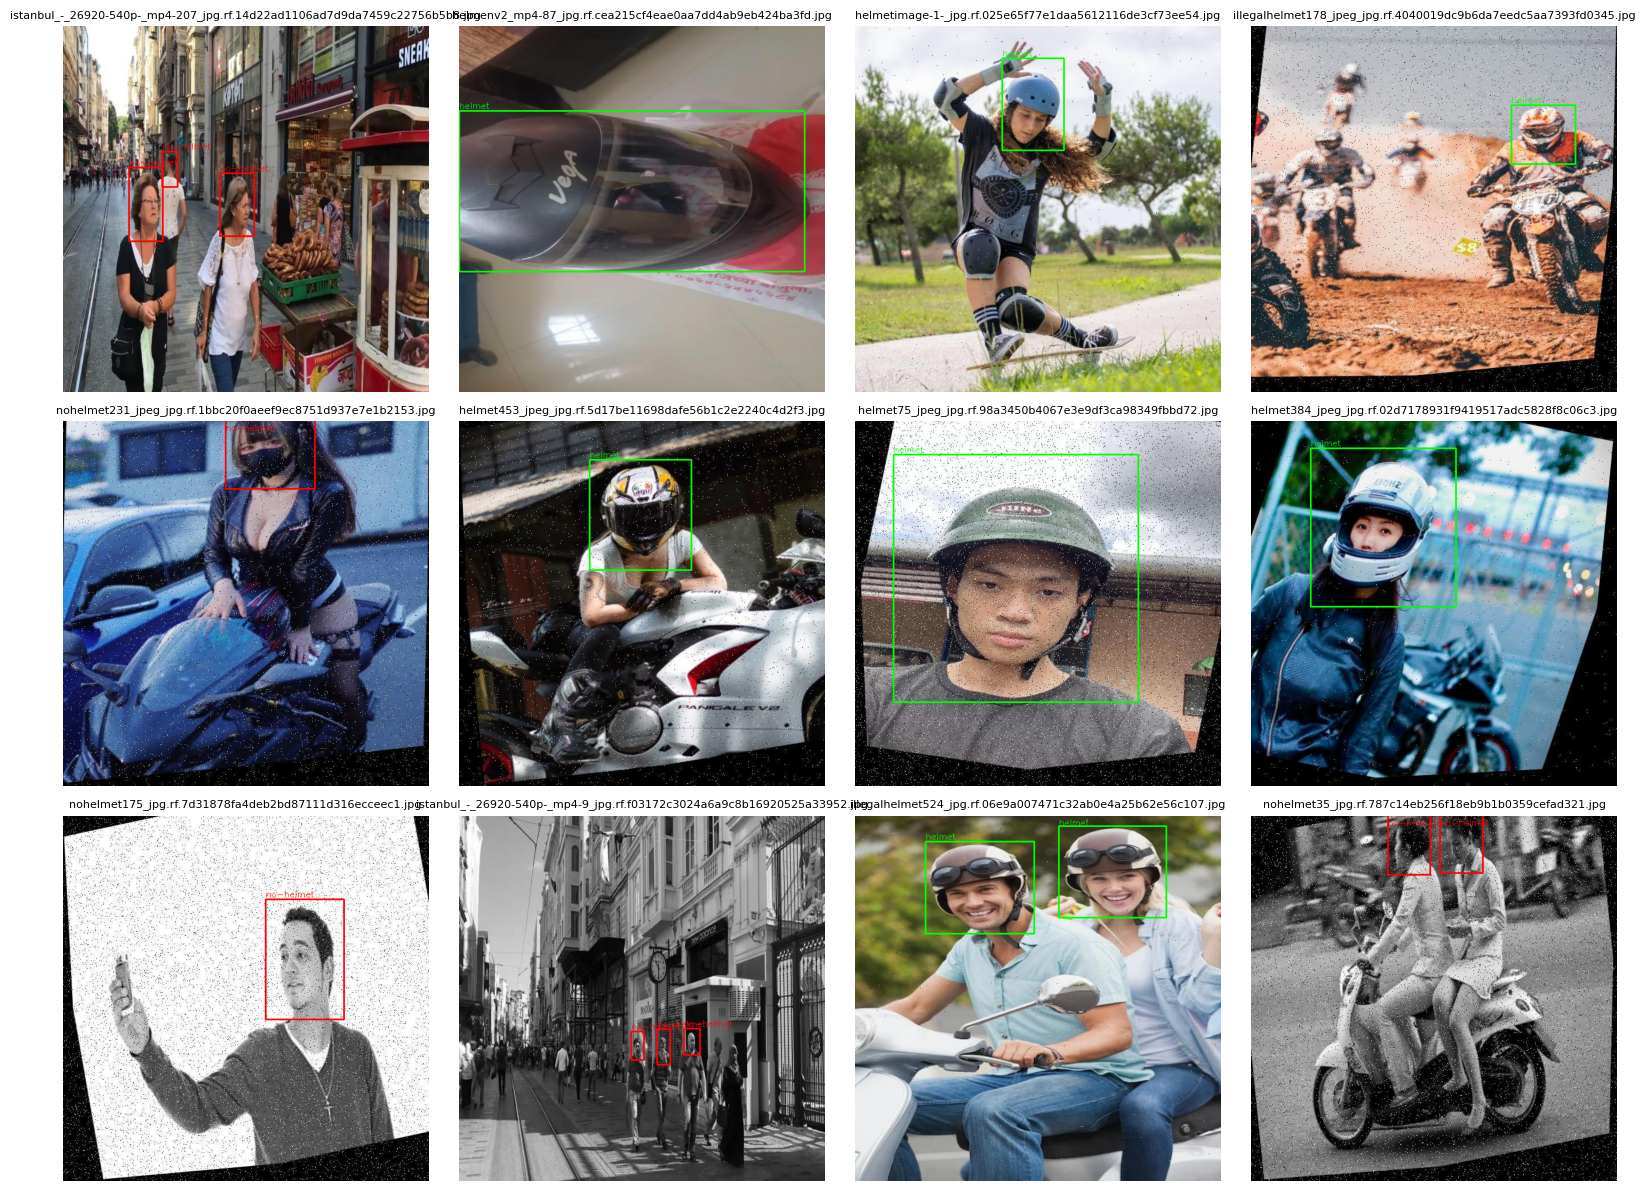

Sample visualization saved: /content/helmet_training/dataset_samples.png


In [7]:
# Save a contact sheet of random annotated training examples for later review.
import cv2
import matplotlib.pyplot as plt

train_images = [p for p in (DATA_ROOT/"train/images").iterdir() if p.suffix.lower() in IMAGE_EXTS]
random.seed(42)
sample_paths = random.sample(train_images, min(12, len(train_images)))
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, img_path in zip(axes.flat, sample_paths):
    img = cv2.imread(str(img_path))
    if img is None:
        ax.axis("off")
        continue
    h, w = img.shape[:2]
    label_path = DATA_ROOT/"train/labels"/(img_path.stem + ".txt")
    if label_path.exists():
        for line in label_path.read_text(errors="ignore").splitlines():
            p = line.split()
            if len(p) != 5:
                continue
            cls = int(float(p[0]))
            xc, yc, bw, bh = map(float, p[1:])
            x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
            x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
            color = (0,255,0) if cls == 0 else (0,0,255)
            cv2.rectangle(img, (x1,y1), (x2,y2), color, 2)
            cv2.putText(img, CLASS_NAMES[cls], (x1,max(18,y1-4)), cv2.FONT_HERSHEY_SIMPLEX, .5, color, 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(img_path.name, fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(sample_paths):]:
    ax.axis("off")
plt.tight_layout()
CONTACT_SHEET = WORK / "dataset_samples.png"
plt.savefig(CONTACT_SHEET, dpi=140)
plt.show()
print("Sample visualization saved:", CONTACT_SHEET)

## 7. Train YOLO11n automatically

The notebook uses transfer learning from the official COCO-pretrained YOLO11n checkpoint. This is normal practice: the model's detection head is fine-tuned on the two helmet classes in this dataset.

The training cell automatically selects GPU if available, uses conservative batch sizing, and saves the best checkpoint.

In [8]:
MODEL_NAME = "yolo11n.pt"
EPOCHS = 50
IMG_SIZE = 640
BATCH = 16 if torch.cuda.is_available() else 4
DEVICE = 0 if torch.cuda.is_available() else "cpu"

model = YOLO(MODEL_NAME)
train_start = time.time()
train_result = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    device=DEVICE,
    workers=2,
    project=str(RUNS),
    name="helmet_nohelmet_yolo11n",
    exist_ok=True,
    pretrained=True,
    patience=12,
    cache=False,
    plots=True,
    save=True,
    amp=True
)
print(f"Training elapsed: {(time.time()-train_start)/60:.1f} minutes")

BEST_PT = RUNS/"helmet_nohelmet_yolo11n/weights/best.pt"
if not BEST_PT.is_file():
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_PT}")
print("Best checkpoint:", BEST_PT, f"({BEST_PT.stat().st_size/1e6:.1f} MB)")

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_training/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_nohelmet_yolo11n, nbs=64, nms=None, opset=None,

## 8. Evaluate validation and test sets

In [9]:
best_model = YOLO(str(BEST_PT))
val_metrics = best_model.val(data=str(DATA_YAML), split="val", imgsz=IMG_SIZE, device=DEVICE, plots=True)
metrics_summary = {
    "validation": {
        "mAP50": float(val_metrics.box.map50),
        "mAP50_95": float(val_metrics.box.map),
        "precision": float(val_metrics.box.mp),
        "recall": float(val_metrics.box.mr)
    }
}
print("Validation:", json.dumps(metrics_summary["validation"], indent=2))

if (DATA_ROOT/"test/images").is_dir():
    test_metrics = best_model.val(data=str(DATA_YAML), split="test", imgsz=IMG_SIZE, device=DEVICE, plots=True)
    metrics_summary["test"] = {
        "mAP50": float(test_metrics.box.map50),
        "mAP50_95": float(test_metrics.box.map),
        "precision": float(test_metrics.box.mp),
        "recall": float(test_metrics.box.mr)
    }
    print("Test:", json.dumps(metrics_summary["test"], indent=2))

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2263.6±1059.1 MB/s, size: 60.3 KB)
val: Scanning /content/helmet_training/dataset/datasetmodelloscelto/dataset10kadjusted/val/labels.cache... 1130 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1130/1130 395.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 71/71 5.8it/s 12.3s
                   all       1130       1832      0.939      0.887      0.932      0.703
                helmet        735       1013      0.935      0.889      0.929      0.755
             no-helmet        425        819      0.943      0.885      0.934      0.652
Speed: 1.4ms preprocess, 3.9ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs/detect/val
Validation: {
  "mAP50": 0.931736431680

## 9. Export ONNX automatically

In [10]:
ONNX_PATH = best_model.export(format="onnx", imgsz=IMG_SIZE, opset=12, simplify=True, dynamic=False)
ONNX_PATH = Path(ONNX_PATH)
print("ONNX exported:", ONNX_PATH, f"({ONNX_PATH.stat().st_size/1e6:.1f} MB)")

import onnxruntime as ort
session = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
print("ONNX input:", session.get_inputs()[0].shape)
print("ONNX output:", session.get_outputs()[0].shape)
print("Class mapping:", best_model.names)

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/helmet_training/runs/helmet_nohelmet_yolo11n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (5.3 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 350ms
Prepared 2 packages in 67ms
Installed 2 packages in 5ms
 + colorama==0.4.6
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.0s, sav

## 10. Run prediction on held-out images and save preview

In [11]:
test_dir = DATA_ROOT/"test/images"
if not test_dir.is_dir():
    test_dir = DATA_ROOT/"val/images"
test_samples = [p for p in test_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS]
random.seed(123)
test_samples = random.sample(test_samples, min(12, len(test_samples)))
PRED_DIR = WORK/"prediction_previews"
PRED_DIR.mkdir(exist_ok=True)
for image_path in test_samples:
    best_model.predict(source=str(image_path), conf=0.25, save=True, project=str(PRED_DIR), name="predictions", exist_ok=True, verbose=False)
print("Prediction previews saved under:", PRED_DIR)

Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Results saved to /content/helmet_training/prediction_previews/predictions
Prediction previews saved under: /content/helmet_training/prediction_previews


## 11. Save all deliverables to Google Drive automatically

In [13]:
# Google Drive requires a one-time Google authorization prompt in Colab.
from google.colab import drive
drive.mount("/content/drive")

DRIVE_OUT = Path("/content/drive/MyDrive/TrafficRulesViolationDetection/helmet_model")
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

shutil.copy2(BEST_PT, DRIVE_OUT/"best.pt")
shutil.copy2(ONNX_PATH, DRIVE_OUT/"helmet_nohelmet.onnx")
shutil.copy2(DATA_YAML, DRIVE_OUT/"data.yaml")
shutil.copy2(CONTACT_SHEET, DRIVE_OUT/"dataset_samples.png")

metadata = {
    "model": "YOLO11n",
    "dataset": "DeBoniz/helmet-detection-dataset",
    "dataset_url": "https://huggingface.co/datasets/DeBoniz/helmet-detection-dataset",
    "dataset_license": "CC BY 4.0",
    "classes": {"0": "helmet", "1": "no-helmet"},
    "epochs_requested": EPOCHS,
    "image_size": IMG_SIZE,
    "batch_size": BATCH,
    "device": str(DEVICE),
    "dataset_split_stats": {
        split: {
            "images": v["images"],
            "boxes": v["boxes"],
            "missing_label_files": v["missing_label_files"],
            "malformed_count": len(v["malformed"])
        } for split, v in stats.items()
    },
    "metrics": metrics_summary,
    "compatibility_warning": "Dataset card labels individuals wearing/not wearing helmets; head-only box semantics are not guaranteed. Existing repository expects head-level detections. Validate and adapt video association before operational use.",
    "artifacts": ["best.pt", "helmet_nohelmet.onnx", "data.yaml", "dataset_samples.png"]
}
(DRIVE_OUT/"training_metadata.json").write_text(json.dumps(metadata, indent=2))
print("\\nTRAINING COMPLETE. SAVED FILES:")
for f in sorted(DRIVE_OUT.iterdir()):
    print(f.name, f"{f.stat().st_size/1e6:.2f} MB")

Mounted at /content/drive
\nTRAINING COMPLETE. SAVED FILES:
best.pt 5.51 MB
data.yaml 0.00 MB
dataset_samples.png 5.55 MB
helmet_nohelmet.onnx 10.66 MB
training_metadata.json 0.00 MB


## 12. Final result

Your Google Drive folder will contain:

- `best.pt` — custom-trained PyTorch model.
- `helmet_nohelmet.onnx` — exported model for your current ONNX inference stack.
- `data.yaml` — class mapping and dataset paths.
- `training_metadata.json` — training configuration, metrics, provenance and compatibility warning.
- `dataset_samples.png` — automatically generated annotation preview.

Expected destination:

`MyDrive/TrafficRulesViolationDetection/helmet_model/`

The only interaction outside code is Google's required one-time Drive authorization. Colab cannot save into your private Drive without your permission.